<a href="https://colab.research.google.com/github/kulanigayathree/J26-IT-364/blob/model%2FFishing-Zone-Prediction/notebooks/C2_fishing_zone_prediction/C2_5_convgru.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# C2 – Notebook 5: ConvGRU (space + time)

**ConvGRU** — like ConvLSTM (space + time) but with a **simpler memory**, so fewer parameters. It answers: *does the extra memory of ConvLSTM help?*

**Same for every model** (so the comparison is fair): same inputs (13 ocean variables + usual fishing
grounds), same 7 input days → Day 1, 2, 3, same split (train 2017–21, validate 2022, test 2023–24),
same loss, early stopping, MC dropout and calibration.

**How the forecast is used:** the 7 input days end **yesterday** (all data then available and matched),
and the model predicts **Day 1 = today, Day 2 = tomorrow, Day 3 = the day after** (72 h).
Fishing data is used only as the **teacher** (training labels), never as an input.


**How to run:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`.
Allow Google Drive access when asked. If Colab disconnects, just `Run all` again: training **continues
from the last saved epoch**. If you change a setting, it starts a new training automatically.

## Step 1 – Connect Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, shutil
BASE = '/content/drive/MyDrive/C2_data'
CKPT_ROOT = f'{BASE}/checkpoints'; os.makedirs(CKPT_ROOT, exist_ok=True)
OUT = f'{BASE}/results';           os.makedirs(OUT, exist_ok=True)
LOCAL_CUBE = '/content/datacube_0p25.nc'
if not os.path.exists(LOCAL_CUBE):                 # copy once to Colab's fast disk (much quicker than reading Drive)
    shutil.copy(f'{BASE}/datacube_0p25.nc', LOCAL_CUBE)
print('Datacube ready:', LOCAL_CUBE)

Mounted at /content/drive
Datacube ready: /content/datacube_0p25.nc


## Step 2 – Settings

In [2]:
import numpy as np, pandas as pd, xarray as xr, time, json, pickle
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.isotonic import IsotonicRegression

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE, '(turn on the T4 GPU if this says cpu)')
torch.manual_seed(42); np.random.seed(42)

# ---- same for EVERY model (fair comparison) ----
T_IN, LEADS = 7, 3                     # 7 input days (ending yesterday) -> Day 1, Day 2, Day 3
TRAIN = ('2017-01-01', '2021-12-31')
VAL   = ('2022-01-01', '2022-12-31')
TEST  = ('2023-01-01', '2024-12-31')
FEATURES = ['sst', 'sst_grad', 'log_chl', 'sla', 'u', 'v', 'cur_speed', 'mld',
            'depth', 'moon_sin', 'moon_cos', 'doy_sin', 'doy_cos',
            'fish_clim']               # usual fishing grounds (monthly map from 2017-21 only)
EPOCHS, BATCH, LR, DROPOUT = 30, 16, 1e-3, 0.2
PATIENCE = 5                           # early stopping
MC_RUNS, CAL_RUNS = 30, 10             # MC dropout runs for test / for fitting calibration

MODEL_NAME, MODEL_LABEL = 'convgru', 'ConvGRU (space + time)'

Device: cuda (turn on the T4 GPU if this says cpu)


## Step 3 – Load the datacube and build the inputs

In [3]:
X = xr.open_dataset(LOCAL_CUBE).load()
days = pd.DatetimeIndex(X.time.values)
ocean = X['depth'].isel(time=0).notnull().values                   # (H, W) True = sea
label = np.nan_to_num(X['fishing'].values).astype('float32')       # (time, H, W) 1 = fishing
tr = (days >= TRAIN[0]) & (days <= TRAIN[1])

# Usual fishing grounds: how often each cell was fished in this month, TRAINING years only.
# It is history, not real-time data, so the model never needs live fishing data.
clim_m = np.stack([label[tr & (days.month == m)].mean(0) for m in range(1, 13)])     # (12, H, W)
X['fish_clim'] = (('time', 'latitude', 'longitude'),
                  np.where(ocean, clim_m[np.asarray(days.month) - 1], np.nan).astype('float32'))

# Features -> (time, channel, H, W), normalised with TRAINING statistics only
feat = np.stack([X[v].values for v in FEATURES], axis=1).astype('float32')
mean = np.nanmean(feat[tr], axis=(0, 2, 3), keepdims=True)
std  = np.nanstd(feat[tr],  axis=(0, 2, 3), keepdims=True) + 1e-6
feat = np.nan_to_num((feat - mean) / std, nan=0.0)                 # land / gaps -> 0

NT, C, H, W = feat.shape
lat, lon = X.latitude.values, X.longitude.values
print(f'{NT} days, {C} input channels, grid {H}x{W}, sea cells {ocean.sum()}')
print('Fishing rate (training years):', round(float(label[tr][:, ocean].mean()), 4))
json.dump({'features': FEATURES, 'mean': mean.ravel().tolist(), 'std': std.ravel().tolist()},
          open(f'{OUT}/normalisation.json', 'w'))

2922 days, 14 input channels, grid 40x44, sea cells 1421
Fishing rate (training years): 0.0046


## Step 4 – Samples and the scoring function

In [4]:
first = np.arange(T_IN - 1, NT - LEADS)                  # t = last input day ("yesterday")
tgt_day = days[first + 1]                                # Day 1 = t + 1 ("today")
def idx(period): return first[(tgt_day >= period[0]) & (tgt_day <= period[1])]
idx_tr, idx_va, idx_te = idx(TRAIN), idx(VAL), idx(TEST)
print('samples  train', len(idx_tr), ' val', len(idx_va), ' test', len(idx_te))

FEAT_T, LAB_T = torch.from_numpy(feat), torch.from_numpy(label)
class Windows(torch.utils.data.Dataset):
    def __init__(self, ids): self.ids = ids
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        t = self.ids[i]
        return FEAT_T[t - T_IN + 1: t + 1], LAB_T[t + 1: t + 1 + LEADS], t

dl_tr = torch.utils.data.DataLoader(Windows(idx_tr), batch_size=BATCH, shuffle=True, drop_last=True)
dl_va = torch.utils.data.DataLoader(Windows(idx_va), batch_size=BATCH)
dl_te = torch.utils.data.DataLoader(Windows(idx_te), batch_size=BATCH)

def scores(prob, ids):
    # prob: (n, LEADS, H, W). Scores sea cells only. PR-AUC is the main score (fishing cells are rare).
    rows = []
    for k in range(LEADS):
        y = label[ids + 1 + k][:, ocean].ravel()
        p = np.clip(prob[:, k][:, ocean].ravel(), 1e-6, 1 - 1e-6)
        rows.append({'lead_day': k + 1, 'PR_AUC': average_precision_score(y, p),
                     'ROC_AUC': roc_auc_score(y, p), 'Brier': brier_score_loss(y, p)})
    return pd.DataFrame(rows).round(4)

samples  train 1819  val 365  test 729


## Step 5 – The model: ConvGRU (space + time)

In [5]:
class ConvGRUCell(nn.Module):
    def __init__(self, cin, ch, k=3):
        super().__init__(); self.ch = ch
        self.gates = nn.Conv2d(cin + ch, 2 * ch, k, padding=k // 2)   # update (z) and reset (r) gates
        self.cand  = nn.Conv2d(cin + ch, ch, k, padding=k // 2)
    def forward(self, x, h):
        z, r = torch.chunk(torch.sigmoid(self.gates(torch.cat([x, h], 1))), 2, 1)
        n = torch.tanh(self.cand(torch.cat([x, r * h], 1)))
        return (1 - z) * h + z * n

class ConvGRUNet(nn.Module):
    # Space + time, like ConvLSTM but a simpler memory (no separate cell state) -> fewer parameters
    def __init__(self, cin, p=0.2, out=3, hidden=(32, 32)):
        super().__init__()
        self.cells = nn.ModuleList(); prev = cin
        for ch in hidden:
            self.cells.append(ConvGRUCell(prev, ch)); prev = ch
        self.drop = nn.Dropout2d(p)
        self.head = nn.Sequential(nn.Conv2d(prev, 32, 3, padding=1), nn.ReLU(),
                                  nn.Dropout2d(p), nn.Conv2d(32, out, 1))
    def forward(self, x):                                  # x: (B, T, C, H, W)
        B, T, _, H, W = x.shape
        state = [x.new_zeros(B, c.ch, H, W) for c in self.cells]
        for t in range(T):
            inp = x[:, t]
            for j, cell in enumerate(self.cells):
                state[j] = cell(inp, state[j])
                inp = self.drop(state[j]) if j < len(self.cells) - 1 else state[j]
        return self.head(self.drop(inp))

MODEL_ARGS = dict(hidden=[32, 32])
def build_model(): return ConvGRUNet(C, p=DROPOUT, out=LEADS, **MODEL_ARGS)

## Step 6 – Train (early stopping, auto-resume)
Loss = binary cross-entropy on sea cells only, with extra weight on the rare fishing cells.
The epoch with the best **validation PR-AUC** is saved as `best.pt`. Training stops early if validation
does not improve for 5 epochs.

convgru: 104,579 parameters
Resuming from epoch 11 (best val PR-AUC 0.2223)
Early stop: no improvement for 5 epochs (best = epoch 5)


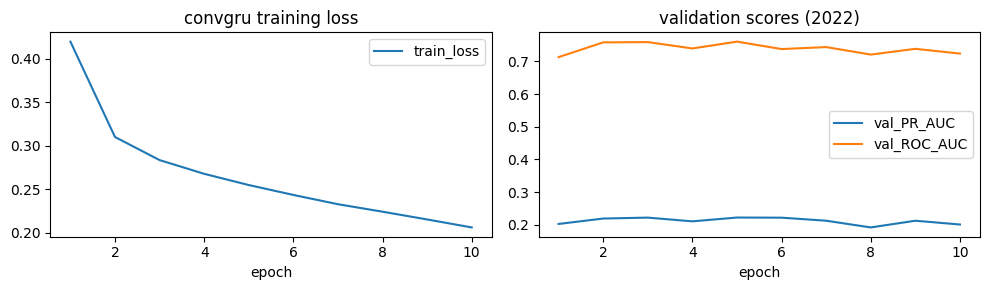

In [6]:
CKPT = f'{CKPT_ROOT}/{MODEL_NAME}'; os.makedirs(CKPT, exist_ok=True)
CONFIG = dict(model=MODEL_NAME, model_args=MODEL_ARGS, features=FEATURES, T_IN=T_IN, LEADS=LEADS,
              BATCH=BATCH, LR=LR, DROPOUT=DROPOUT)
json.dump(CONFIG, open(f'{OUT}/{MODEL_NAME}_config.json', 'w'))
model = build_model().to(DEVICE)
print(f'{MODEL_NAME}: {sum(p.numel() for p in model.parameters()):,} parameters')

mask_dev = torch.from_numpy(ocean.astype('float32')).to(DEVICE)
pos = label[tr][:, ocean].mean()
pos_weight = torch.tensor((1 - pos) / max(pos, 1e-4)).clamp(max=50).to(DEVICE)   # fishing cells are rare
LOG_W = torch.log(pos_weight)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)

def masked_loss(logits, y):
    l = F.binary_cross_entropy_with_logits(logits, y, pos_weight=pos_weight, reduction='none')
    m = mask_dev.expand_as(l)
    return (l * m).sum() / m.sum()

def enable_mc(m):
    # MC dropout: dropout ON, everything else (e.g. BatchNorm) in normal prediction mode
    m.eval()
    for layer in m.modules():
        if isinstance(layer, (nn.Dropout, nn.Dropout2d)): layer.train()

@torch.no_grad()
def predict(dl, runs=1, calib=None):
    enable_mc(model) if runs > 1 else model.eval()
    means, stds, ids = [], [], []
    for xb, _, tb in dl:
        xb = xb.to(DEVICE)
        ps = torch.stack([torch.sigmoid(model(xb) - LOG_W) for _ in range(runs)]).cpu().numpy()
        if calib is not None:
            for k in range(LEADS):
                ps[:, :, k] = calib[k].predict(ps[:, :, k].ravel()).reshape(ps[:, :, k].shape)
        means.append(ps.mean(0)); stds.append(ps.std(0)); ids.append(tb.numpy())
    return np.concatenate(means), np.concatenate(stds), np.concatenate(ids)

# ---- resume if a previous run with the SAME settings exists ----
start_epoch, best, best_ep, history = 0, -1.0, -1, []
if os.path.exists(f'{CKPT}/last.pt'):
    ck = torch.load(f'{CKPT}/last.pt', map_location=DEVICE, weights_only=False)
    if ck.get('config') == CONFIG:
        model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt']); sched.load_state_dict(ck['sched'])
        start_epoch, best, best_ep, history = ck['epoch'] + 1, ck['best'], ck['best_ep'], ck['history']
        print(f'Resuming from epoch {start_epoch + 1} (best val PR-AUC {best:.4f})')
    else:
        print('Settings changed since last run -> starting a NEW training')

for ep in range(start_epoch, EPOCHS):
    if best_ep >= 0 and ep - best_ep > PATIENCE:
        print(f'Early stop: no improvement for {PATIENCE} epochs (best = epoch {best_ep + 1})'); break
    model.train(); t0 = time.time(); tot = 0
    for xb, yb, _ in dl_tr:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        loss = masked_loss(model(xb), yb)
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        tot += loss.item()
    sched.step()
    pv, _, iv = predict(dl_va)
    va = scores(pv, iv); pr = float(va.PR_AUC.mean())
    history.append({'epoch': ep + 1, 'train_loss': tot / len(dl_tr), 'val_PR_AUC': pr, 'val_ROC_AUC': float(va.ROC_AUC.mean())})
    improved = pr > best
    if improved:
        best, best_ep = pr, ep; torch.save(model.state_dict(), f'{CKPT}/best.pt')
    torch.save({'model': model.state_dict(), 'opt': opt.state_dict(), 'sched': sched.state_dict(), 'epoch': ep,
                'best': best, 'best_ep': best_ep, 'history': history, 'config': CONFIG}, f'{CKPT}/last.pt')
    print(f'epoch {ep+1:2d}/{EPOCHS}  loss {tot/len(dl_tr):.4f}  val PR-AUC {pr:.4f}  '
          f'ROC-AUC {va.ROC_AUC.mean():.4f}  ({time.time()-t0:.0f}s){"  *best*" if improved else ""}')

h = pd.DataFrame(history)
pd.DataFrame(history).to_csv(f'{OUT}/{MODEL_NAME}_history.csv', index=False)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
h.plot(x='epoch', y='train_loss', ax=ax[0]); h.plot(x='epoch', y=['val_PR_AUC', 'val_ROC_AUC'], ax=ax[1])
ax[0].set_title(f'{MODEL_NAME} training loss'); ax[1].set_title('validation scores (2022)')
plt.tight_layout(); plt.show()

## Step 7 – Calibrate on 2022, then test on 2023–24 with MC dropout
**Calibration** fixes probabilities that are too low/high (fitted on 2022 only).
**MC dropout**: 30 runs with dropout ON → mean = probability, spread = uncertainty.

In [7]:
model.load_state_dict(torch.load(f'{CKPT}/best.pt', map_location=DEVICE))

# 1) Calibration, fitted on the 2022 validation year only (never on test years)
pv, _, iv = predict(dl_va, runs=CAL_RUNS)
calib = [IsotonicRegression(out_of_bounds='clip', y_min=0, y_max=1)
         .fit(pv[:, k][:, ocean].ravel(), label[iv + 1 + k][:, ocean].ravel()) for k in range(LEADS)]
pickle.dump(calib, open(f'{OUT}/{MODEL_NAME}_calibrator.pkl', 'wb'))
pv_cal = np.stack([calib[k].predict(pv[:, k].ravel()).reshape(pv[:, k].shape) for k in range(LEADS)], 1)
val_df = scores(pv_cal, iv); val_df.insert(0, 'model', MODEL_LABEL)
val_df.to_csv(f'{OUT}/{MODEL_NAME}_val_scores.csv', index=False)

# 2) Test 2023-24: MC dropout (probability + uncertainty), calibrated
p_mean, p_std, ids_te = predict(dl_te, runs=MC_RUNS, calib=calib)
test_df = scores(p_mean, ids_te); test_df.insert(0, 'model', MODEL_LABEL)
test_df.to_csv(f'{OUT}/{MODEL_NAME}_test_scores.csv', index=False)
np.savez_compressed(f'{OUT}/{MODEL_NAME}_test_predictions.npz', mean=p_mean.astype('float16'),
                    std=p_std.astype('float16'), ids=ids_te)

print('VALIDATION 2022 (used to choose the best model)'); print(val_df.to_string(index=False))
print('\nTEST 2023-24 (final result for the report)');    print(test_df.to_string(index=False))
print('\nAverage predicted probability:', round(float(p_mean[:, 0][:, ocean].mean()), 3),
      '| real fishing rate:', round(float(label[ids_te + 1][:, ocean].mean()), 3), ' (should be close)')

VALIDATION 2022 (used to choose the best model)
                 model  lead_day  PR_AUC  ROC_AUC  Brier
ConvGRU (space + time)         1  0.2167   0.7597 0.0638
ConvGRU (space + time)         2  0.2172   0.7598 0.0639
ConvGRU (space + time)         3  0.2178   0.7612 0.0641

TEST 2023-24 (final result for the report)
                 model  lead_day  PR_AUC  ROC_AUC  Brier
ConvGRU (space + time)         1  0.2831   0.6952 0.1159
ConvGRU (space + time)         2  0.2838   0.6958 0.1158
ConvGRU (space + time)         3  0.2844   0.6966 0.1158

Average predicted probability: 0.067 | real fishing rate: 0.138  (should be close)


## Step 8 – Reliability check and example maps

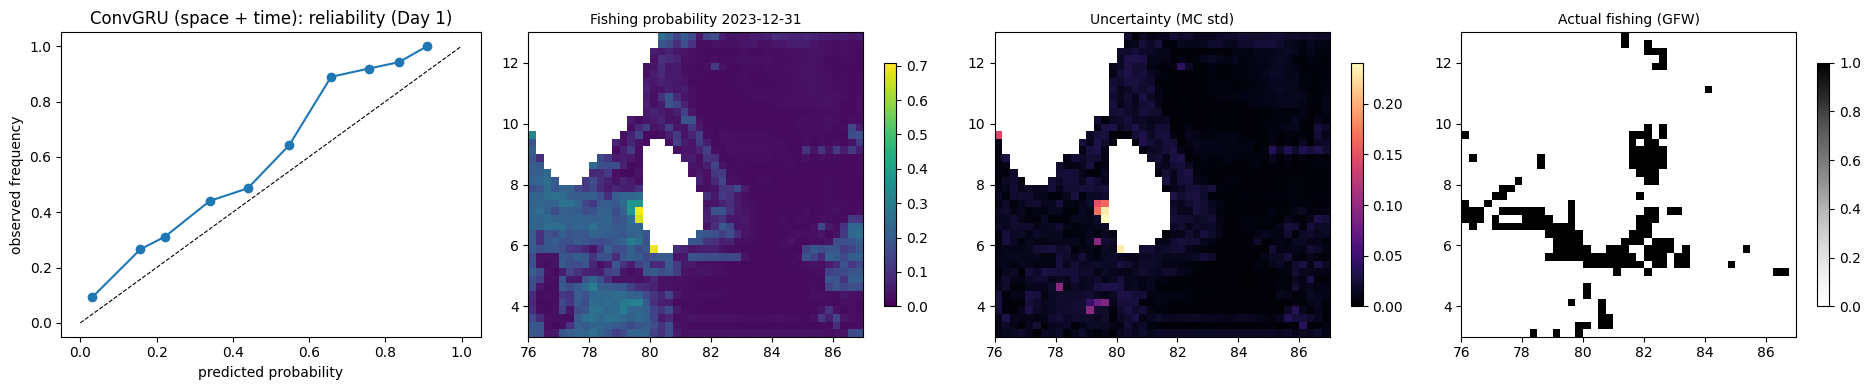

In [8]:
y = label[ids_te + 1][:, ocean].ravel(); p = p_mean[:, 0][:, ocean].ravel()
b = np.digitize(p, np.linspace(0, 1, 11)) - 1
rel = pd.DataFrame({'b': b, 'p': p, 'y': y}).groupby('b').agg(pred=('p', 'mean'), obs=('y', 'mean'))

d = len(ids_te) // 2                                     # a mid-test day
def show(ax, a, title, cmap, vmin=None, vmax=None):
    im = ax.pcolormesh(lon, lat, np.where(ocean, a, np.nan), cmap=cmap, shading='auto', vmin=vmin, vmax=vmax)
    ax.set_title(title, fontsize=10); ax.set_aspect('equal'); plt.colorbar(im, ax=ax, shrink=0.8)

fig, ax = plt.subplots(1, 4, figsize=(19, 4))
ax[0].plot([0, 1], [0, 1], 'k--', lw=0.8); ax[0].plot(rel.pred, rel.obs, 'o-')
ax[0].set_xlabel('predicted probability'); ax[0].set_ylabel('observed frequency')
ax[0].set_title(f'{MODEL_LABEL}: reliability (Day 1)')
when = days[ids_te[d] + 1].date()
show(ax[1], p_mean[d, 0], f'Fishing probability {when}', 'viridis', 0)
show(ax[2], p_std[d, 0], 'Uncertainty (MC std)', 'magma', 0)
show(ax[3], label[ids_te[d] + 1], 'Actual fishing (GFW)', 'Greys', 0, 1)
plt.tight_layout(); plt.savefig(f'{OUT}/{MODEL_NAME}_example_maps.png', dpi=120); plt.show()

In [9]:
# ===== TUNING (ConvGRU): try settings, choose by VALIDATION 2022 PR-AUC only =====
# Each trial trains a fresh ConvGRU. Results are saved after every trial, so if Colab
# disconnects, run this cell again and finished trials are skipped.
TRIALS = [
    dict(name='base (32,32 / drop 0.2 / lr 1e-3 / 7 days)', hidden=[32, 32],     DROPOUT=0.2, LR=1e-3, T_IN=7),
    dict(name='dropout 0.3',                              hidden=[32, 32],     DROPOUT=0.3, LR=1e-3, T_IN=7),
    dict(name='dropout 0.4',                              hidden=[32, 32],     DROPOUT=0.4, LR=1e-3, T_IN=7),
    dict(name='learning rate 3e-4',                       hidden=[32, 32],     DROPOUT=0.2, LR=3e-4, T_IN=7),
    dict(name='smaller (16,16)',                          hidden=[16, 16],     DROPOUT=0.2, LR=1e-3, T_IN=7),
    dict(name='bigger (64,64)',                           hidden=[64, 64],     DROPOUT=0.2, LR=1e-3, T_IN=7),
    dict(name='deeper (32,32,32)',                        hidden=[32, 32, 32], DROPOUT=0.2, LR=1e-3, T_IN=7),
    dict(name='3 input days',                             hidden=[32, 32],     DROPOUT=0.2, LR=1e-3, T_IN=3),
    dict(name='14 input days',                            hidden=[32, 32],     DROPOUT=0.2, LR=1e-3, T_IN=14),
]
TUNE_EPOCHS, TUNE_PATIENCE = 20, 4
TUNE_CSV = f'{OUT}/convgru_tuning.csv'

class WindowsT(torch.utils.data.Dataset):
    def __init__(self, ids, t_in): self.ids, self.t_in = ids, t_in
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        t = self.ids[i]
        return FEAT_T[t - self.t_in + 1: t + 1], LAB_T[t + 1: t + 1 + LEADS], t

def run_trial(cfg, seed=42):
    torch.manual_seed(seed); np.random.seed(seed)
    t_in = cfg['T_IN']
    first_ = np.arange(t_in - 1, NT - LEADS); tgt = days[first_ + 1]
    sel = lambda per: first_[(tgt >= per[0]) & (tgt <= per[1])]
    dtr = torch.utils.data.DataLoader(WindowsT(sel(TRAIN), t_in), batch_size=BATCH, shuffle=True, drop_last=True)
    dva = torch.utils.data.DataLoader(WindowsT(sel(VAL), t_in), batch_size=BATCH)
    m = ConvGRUNet(C, p=cfg['DROPOUT'], out=LEADS, hidden=cfg['hidden']).to(DEVICE)
    o = torch.optim.AdamW(m.parameters(), lr=cfg['LR'], weight_decay=1e-4)
    s = torch.optim.lr_scheduler.CosineAnnealingLR(o, T_max=TUNE_EPOCHS)
    best_pr, best_ep, t0 = -1.0, 0, time.time()
    for ep in range(1, TUNE_EPOCHS + 1):
        m.train()
        for xb, yb, _ in dtr:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            l = F.binary_cross_entropy_with_logits(m(xb), yb, pos_weight=pos_weight, reduction='none')
            mk = mask_dev.expand_as(l); loss = (l * mk).sum() / mk.sum()
            o.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(m.parameters(), 1.0); o.step()
        s.step()
        m.eval(); ps, ids = [], []
        with torch.no_grad():
            for xb, _, tb in dva:
                ps.append(torch.sigmoid(m(xb.to(DEVICE))).cpu().numpy()); ids.append(tb.numpy())
        pr = float(scores(np.concatenate(ps), np.concatenate(ids)).PR_AUC.mean())
        if pr > best_pr: best_pr, best_ep = pr, ep
        elif ep - best_ep >= TUNE_PATIENCE: break
    return best_pr, best_ep, (time.time() - t0) / 60, sum(p.numel() for p in m.parameters())

tune = pd.read_csv(TUNE_CSV) if os.path.exists(TUNE_CSV) else pd.DataFrame()
for cfg in TRIALS:
    if len(tune) and cfg['name'] in set(tune['name']):
        print('skip (already done):', cfg['name']); continue
    print('running:', cfg['name'], '...', end=' ', flush=True)
    pr, ep, mins, npar = run_trial(cfg)
    row = {**cfg, 'hidden': str(cfg['hidden']), 'val_PR_AUC': round(pr, 4), 'best_epoch': ep,
           'params': npar, 'minutes': round(mins, 1)}
    tune = pd.concat([tune, pd.DataFrame([row])], ignore_index=True); tune.to_csv(TUNE_CSV, index=False)
    print(f'val PR-AUC {pr:.4f}  (best epoch {ep}, {mins:.1f} min)')
print('\nAll trials done. Results saved to results/convgru_tuning.csv')

running: base (32,32 / drop 0.2 / lr 1e-3 / 7 days) ... val PR-AUC 0.2219  (best epoch 3, 1.1 min)
running: dropout 0.3 ... val PR-AUC 0.2252  (best epoch 5, 1.4 min)
running: dropout 0.4 ... val PR-AUC 0.2237  (best epoch 5, 1.4 min)
running: learning rate 3e-4 ... val PR-AUC 0.2184  (best epoch 2, 0.9 min)
running: smaller (16,16) ... val PR-AUC 0.2226  (best epoch 3, 0.6 min)
running: bigger (64,64) ... val PR-AUC 0.2266  (best epoch 1, 1.5 min)
running: deeper (32,32,32) ... val PR-AUC 0.2173  (best epoch 1, 1.0 min)
running: 3 input days ... val PR-AUC 0.2264  (best epoch 8, 0.8 min)
running: 14 input days ... val PR-AUC 0.2311  (best epoch 4, 2.4 min)

All trials done. Results saved to results/convgru_tuning.csv


In [9]:
# ===== Tuning results: best settings by validation PR-AUC =====
tune = pd.read_csv(TUNE_CSV).sort_values('val_PR_AUC', ascending=False).reset_index(drop=True)
base = tune.loc[tune.name.str.startswith('base'), 'val_PR_AUC'].iloc[0]
tune['vs base'] = (tune.val_PR_AUC - base).round(4)
print(tune[['name', 'hidden', 'DROPOUT', 'LR', 'T_IN', 'val_PR_AUC', 'vs base', 'best_epoch', 'params']].to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 0.45 * len(tune) + 1))
ax.barh(tune.name[::-1], tune.val_PR_AUC[::-1], color=['tab:red' if n.startswith('base') else 'tab:blue' for n in tune.name[::-1]])
ax.set_xlim(tune.val_PR_AUC.min() - 0.01, tune.val_PR_AUC.max() + 0.005)
ax.set_xlabel('validation PR-AUC (2022)'); ax.set_title('ConvGRU tuning (red = original settings)')
plt.tight_layout(); plt.savefig(f'{OUT}/convgru_tuning.png', dpi=130); plt.show()

b = tune.iloc[0]
print(f"\nBEST: {b['name']}  (val PR-AUC {b.val_PR_AUC:.4f}, {b['vs base']:+.4f} vs base)")
print('To use it, set these and Run all again:')
print(f"  Step 2:  T_IN, LEADS = {int(b.T_IN)}, 3")
print(f"           EPOCHS, BATCH, LR, DROPOUT = 30, 16, {b.LR:g}, {b.DROPOUT:g}")
print(f"  Step 5:  MODEL_ARGS = dict(hidden={b.hidden})")

In [10]:
# ===== (Optional) Is the improvement real? Repeat best and base with 3 different seeds =====
best_cfg = next(c for c in TRIALS if c['name'] == tune.iloc[0]['name'])
base_cfg = TRIALS[0]
rows = []
for cfg in ([base_cfg, best_cfg] if best_cfg is not base_cfg else [base_cfg]):
    for seed in [1, 2, 3]:
        pr, ep, mins, _ = run_trial(cfg, seed=seed)
        rows.append({'name': cfg['name'], 'seed': seed, 'val_PR_AUC': round(pr, 4)})
        print(cfg['name'], 'seed', seed, f'-> {pr:.4f}')
seeds = pd.DataFrame(rows)
summary = seeds.groupby('name').val_PR_AUC.agg(['mean', 'std']).round(4)
print('\n', summary.to_string())
seeds.to_csv(f'{OUT}/convgru_tuning_seeds.csv', index=False)

base (32,32 / drop 0.2 / lr 1e-3 / 7 days) seed 1 -> 0.2212
base (32,32 / drop 0.2 / lr 1e-3 / 7 days) seed 2 -> 0.2304
base (32,32 / drop 0.2 / lr 1e-3 / 7 days) seed 3 -> 0.2281

                                               mean     std
name                                                      
base (32,32 / drop 0.2 / lr 1e-3 / 7 days)  0.2266  0.0048


**Saved to Drive (`C2_data/`):** `checkpoints/convgru/best.pt`, `results/convgru_config.json`,
`results/convgru_calibrator.pkl`, `results/convgru_val_scores.csv`, `results/convgru_test_scores.csv`,
`results/convgru_test_predictions.npz`, `results/convgru_history.csv`, `results/convgru_example_maps.png`.

Next: run the other model notebooks, then **`C2_6_compare_models`**.